# UBC Vancouver Student Housing: Capacity, Waitlists & Rental Costs

**Research question.** How has reported on-campus housing capacity changed relative to enrolment at UBC Vancouver, and what do published waitlist milestones and nearby rental-market data reveal about student housing pressures?

**Why it matters.** Access to campus housing can affect students' budgets, commuting time, and university experience. By combining public data on enrolment, residence capacity, waitlists, and rental costs, this project examines the scale of the issue while recognizing that students have different housing needs and outcomes.

**Scope.** UBC Vancouver, with enrolment data from 2015/16 to 2024/25, dated residence-bed and waitlist milestones, CMHC rental data from 2016 to 2025, a 2025 rental-zone snapshot, and 2026/27 residence fees.

**Data provenance.** Public sources are documented in `SOURCES.md`, and source IDs are included in the supporting CSV files. Missing annual bed-count and waitlist observations are not interpolated. Derived calculations and hypothetical scenarios are identified and interpreted with appropriate limitations.

**Ethics.** This analysis uses aggregate institutional and rental-market data only. It contains no individual applications, identities, or waitlist positions.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Locate the CSVs wherever they sit: alongside this notebook, or in a
# data/raw subfolder. Keeps the notebook runnable without a fixed layout.
RAW = next((p for p in [Path("."), Path("data/raw"), Path("../data/raw"), Path("..")]
            if (p / "ubc_enrolment_vancouver.csv").exists()), None)
if RAW is None:
    raise FileNotFoundError("CSVs not found. Put them beside this notebook or in data/raw.")

FIG = Path("figures"); FIG.mkdir(exist_ok=True)
print(f"Reading data from: {RAW.resolve()}")

plt.rcParams.update({
    "figure.figsize": (10, 5.5), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 11,
})
ACCENT, WARN, MUTE = "#2b5c8f", "#b22222", "#8a94a0"

enrolment = pd.read_csv(RAW / "ubc_enrolment_vancouver.csv")
beds      = pd.read_csv(RAW / "ubc_housing_beds.csv")
waitlist  = pd.read_csv(RAW / "ubc_waitlist.csv")
rent      = pd.read_csv(RAW / "cmhc_vancouver_cma_avg_rent.csv")
zones     = pd.read_csv(RAW / "cmhc_zone_2025.csv")
fees      = pd.read_csv(RAW / "ubc_residence_fees_2026_27.csv")

for n, d in [("enrolment", enrolment), ("beds", beds), ("waitlist", waitlist),
             ("rent", rent), ("zones", zones), ("fees", fees)]:
    print(f"{n:10s} {d.shape[0]:3d} rows x {d.shape[1]} cols")

Reading data from: /mnt/data/housing_cleanrun
enrolment   10 rows x 5 cols
beds         4 rows x 5 cols
waitlist     5 rows x 4 cols
rent        10 rows x 7 cols
zones        6 rows x 10 cols
fees         9 rows x 7 cols


## 1. What the data can and cannot support

The sources are uneven, and that shapes every claim made later, so it is worth stating the coverage before any analysis.

In [2]:
coverage = pd.DataFrame([
    {"series": "Enrolment (Vancouver)",   "span": "2015/16-2024/25", "n": len(enrolment), "kind": "annual, two official report editions"},
    {"series": "Residence beds",          "span": "2019-2024",       "n": len(beds),      "kind": "dated statements, not an annual series"},
    {"series": "Housing waitlist",        "span": "2010-2025",       "n": len(waitlist),  "kind": "point-in-time, rounded by the speaker"},
    {"series": "CMHC rent (CMA)",         "span": "2016-2025",       "n": len(rent),      "kind": "annual survey, October reference"},
    {"series": "CMHC rent/vacancy (zone)","span": "2025 only",       "n": len(zones),     "kind": "single-period zone cross-section"},
    {"series": "Residence fees",          "span": "2026/27 only",    "n": len(fees),      "kind": "single-year snapshot"},
])
coverage

,series,span,n,kind
0,Enrolment (Vancouver),2015/16-2024/25,10,"annual, two official report editions"
1,Residence beds,2019-2024,4,"dated statements, not an annual series"
2,Housing waitlist,2010-2025,5,"point-in-time, rounded by the speaker"
3,CMHC rent (CMA),2016-2025,10,"annual survey, October reference"
4,CMHC rent/vacancy (zone),2025 only,6,single-period zone cross-section
5,Residence fees,2026/27 only,9,single-year snapshot


Two series are sparse. Bed counts and waitlist figures are statements made at particular moments in announcements and news coverage; UBC publishes neither as a continuous table.

That drives one rule applied throughout: **sparse series are plotted as marked observations and never interpolated.** A smooth line through four bed figures would imply precision the sources do not have. Where a rate of change is needed, it is computed between two dated observations and described as such.

In [3]:
# UBC's own bed totals do not reconcile. Surface it rather than smooth it.
b = beds.set_index("as_of_year")["vancouver_beds"]
implied = b.loc[2023] + 282          # Brock Commons South added 282 beds

print(f"2023 reported total (post Brock North) : {b.loc[2023]:,}")
print(f"+ Brock South (282 beds)               : {implied:,}")
print(f"2024 reported total (post Brock South) : {b.loc[2024]:,}")
print(f"Unexplained difference                 : {b.loc[2024] - implied:,} beds")

2023 reported total (post Brock North) : 13,205
+ Brock South (282 beds)               : 13,487
2024 reported total (post Brock South) : 13,883
Unexplained difference                 : 396 beds


UBC's published totals do not reconcile with the building announcement. The 2023 reported total of 13,205 plus the 282 beds announced for Brock Commons South gives 13,487, while UBC reported 13,883 for 2024/25. The reason for the 396-bed difference is not established by the sources reviewed.

I keep the published total visible rather than silently correcting it, and compare the results under both totals where relevant.


## 2. Capacity relative to enrolment

Beds per 1,000 students is the comparable measure: it answers how much residence capacity exists per unit of student population, and stays meaningful as enrolment moves.

In [4]:
cap = enrolment.copy()

cap["year"] = cap["academic_year"].str[:4].astype(int)

cap = cap.merge(
    beds[["as_of_year", "vancouver_beds"]],
    left_on="year",
    right_on="as_of_year",
    how="left"
)

# Compare published residence capacity with total enrolment.
# This is a capacity ratio, not actual campus occupancy.
cap["beds_per_1000"] = (
    cap["vancouver_beds"] / cap["total_headcount"] * 1000
)

cap["capacity_pct_of_enrolment"] = (
    cap["vancouver_beds"] / cap["total_headcount"] * 100
)

cap["intl_pct"] = (
    cap["international_headcount"]
    / cap["total_headcount"] * 100
)

display(
    cap[
        [
            "academic_year",
            "total_headcount",
            "international_headcount",
            "intl_pct",
            "vancouver_beds",
            "beds_per_1000",
            "capacity_pct_of_enrolment",
        ]
    ].round(1)
)

,academic_year,total_headcount,international_headcount,intl_pct,vancouver_beds,beds_per_1000,capacity_pct_of_enrolment
0,2015/16,52721,12117,23.0,NaN,NaN,NaN
1,2016/17,54232,13182,24.3,NaN,NaN,NaN
2,2017/18,55780,14685,26.3,NaN,NaN,NaN
3,2018/19,56331,15405,27.3,NaN,NaN,NaN
4,2019/20,57250,16098,28.1,11800.0,206.1,20.6
5,2020/21,58462,15504,26.5,12000.0,205.3,20.5
6,2021/22,60292,16804,27.9,NaN,NaN,NaN
7,2022/23,60607,17243,28.5,NaN,NaN,NaN
8,2023/24,60863,17019,28.0,13205.0,217.0,21.7
9,2024/25,60944,16357,26.8,13883.0,227.8,22.8


In [5]:
# Compare the two years with available bed counts,
# then test the unresolved 2024 bed-count discrepancy.

start = cap.loc[
    cap["academic_year"] == "2020/21"
].iloc[0]

latest = cap.loc[
    cap["academic_year"] == "2024/25"
].iloc[0]

beds_2024_alternative = int(b.loc[2023] + 282)

enrolment_growth = (
    latest["total_headcount"] / start["total_headcount"] - 1
) * 100

beds_growth_reported = (
    latest["vancouver_beds"] / start["vancouver_beds"] - 1
) * 100

beds_growth_alternative = (
    beds_2024_alternative / start["vancouver_beds"] - 1
) * 100

alternative_capacity_per_1000 = (
    beds_2024_alternative / latest["total_headcount"] * 1000
)

print("ENROLMENT AND HOUSING CAPACITY")
print(
    f"Enrolment growth, 2020/21–2024/25: "
    f"{enrolment_growth:.1f}%"
)

print(
    f"Bed-count growth using published totals: "
    f"{beds_growth_reported:.1f}%"
)

print(
    f"Bed-count growth using the alternative 2024 total: "
    f"{beds_growth_alternative:.1f}%"
)

print()
print(
    f"2020/21: {start['beds_per_1000']:.1f} beds per 1,000 students"
)

print(
    f"2024/25, published total: "
    f"{latest['beds_per_1000']:.1f} beds per 1,000 students"
)

print(
    f"2024/25, alternative total: "
    f"{alternative_capacity_per_1000:.1f} beds per 1,000 students"
)

print()
print(
    "The alternative is a sensitivity scenario, not a corrected "
    "official total. The discrepancy remains unresolved."
)

ENROLMENT AND HOUSING CAPACITY
Enrolment growth, 2020/21–2024/25: 4.2%
Bed-count growth using published totals: 15.7%
Bed-count growth using the alternative 2024 total: 12.4%

2020/21: 205.3 beds per 1,000 students
2024/25, published total: 227.8 beds per 1,000 students
2024/25, alternative total: 221.3 beds per 1,000 students

The alternative is a sensitivity scenario, not a corrected official total. The discrepancy remains unresolved.


Reported residence capacity relative to enrolment increased between 2020/21 and 2024/25. Using the published bed totals, capacity rose from approximately 205 to 228 beds per 1,000 students.

However, UBC's published 2024 total does not reconcile with the 2023 total plus the 282 beds announced for Brock Commons South. Using that alternative total gives approximately 221 beds per 1,000 students.

The direction of the finding is unchanged: reported capacity increased relative to enrolment under either calculation. These ratios measure potential capacity, not actual occupancy, and do not establish how many individual students live on campus or need housing.

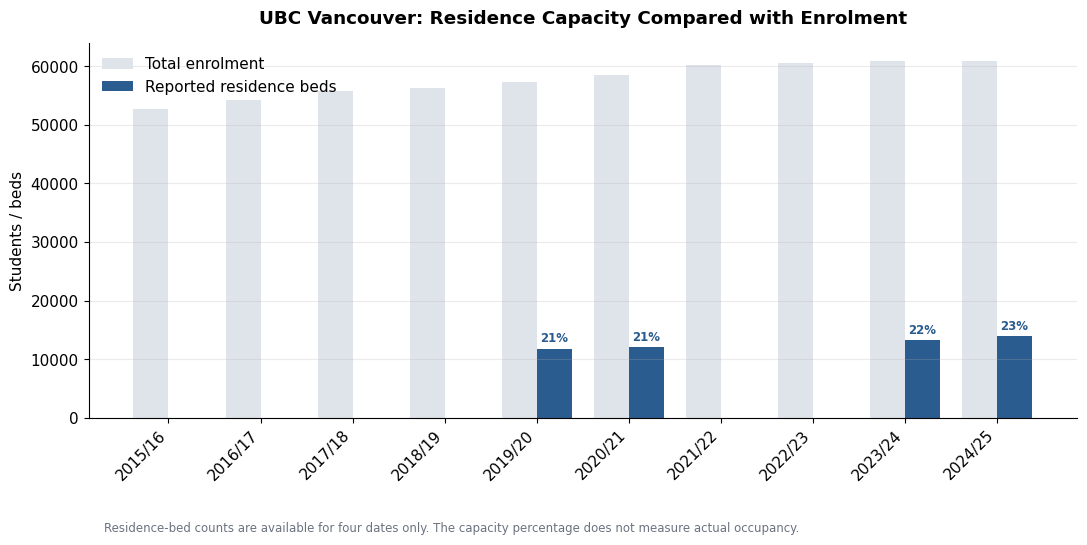

In [6]:
# Visualize reported residence capacity against enrolment

plot_data = cap.reset_index(drop=True).copy()

x = np.arange(len(plot_data))
width = 0.38
has_beds = plot_data["vancouver_beds"].notna()

fig, ax = plt.subplots(figsize=(11, 5.5))

# Show enrolment for each academic year
ax.bar(
    x - width / 2,
    plot_data["total_headcount"],
    width,
    color="#dfe4ea",
    label="Total enrolment"
)

# Show residence beds only where a sourced count exists
ax.bar(
    x[has_beds] + width / 2,
    plot_data.loc[has_beds, "vancouver_beds"],
    width,
    color=ACCENT,
    label="Reported residence beds"
)

# Label observed capacity as a percentage of enrolment
for i in np.flatnonzero(has_beds):
    r = plot_data.iloc[i]

    ax.annotate(
        f"{r['capacity_pct_of_enrolment']:.0f}%",
        (x[i] + width / 2, r["vancouver_beds"]),
        textcoords="offset points",
        xytext=(0, 5),
        ha="center",
        fontsize=8.5,
        color=ACCENT,
        fontweight="bold"
    )

ax.set_title(
    "UBC Vancouver: Residence Capacity Compared with Enrolment",
    fontweight="bold",
    pad=14
)

ax.set_ylabel("Students / beds")
ax.set_xticks(x)
ax.set_xticklabels(
    plot_data["academic_year"],
    rotation=45,
    ha="right"
)

ax.legend(frameon=False, loc="upper left")
ax.grid(axis="x", visible=False)

fig.text(
    0.10,
    0.02,
    "Residence-bed counts are available for four dates only. "
    "The capacity percentage does not measure actual occupancy.",
    fontsize=8.5,
    color="#6b7280"
)

fig.tight_layout(rect=[0, 0.08, 1, 1])

plt.savefig(
    FIG / "capacity_vs_enrolment.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## 3. Enrollment Trends and Potential Housing Demand

Total enrolment grew over the period, but enrolment data alone cannot tell us how many students need residence. International enrolment is one useful measure to monitor alongside other evidence, but it does not directly measure housing needs, residence applications, or waitlist entries.


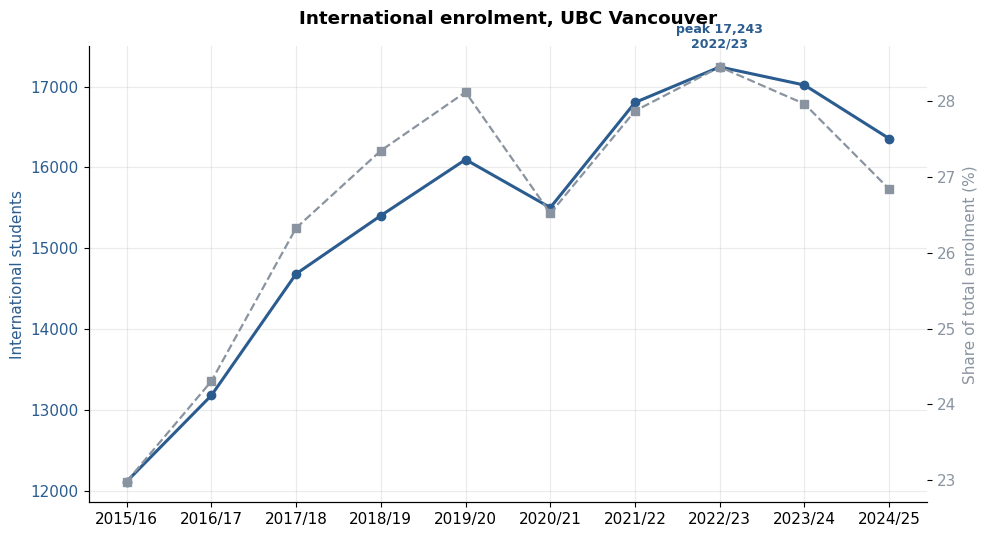

2015/16: 12,117 international (23.0% of enrolment)
2022/23: 17,243 (+42% from 2015/16)
2024/25: 16,357 (-5% from peak)


In [7]:
fig, ax1 = plt.subplots()
ax1.plot(cap["academic_year"], cap["international_headcount"], marker="o",
         color=ACCENT, linewidth=2.2, label="International headcount")
ax1.set_ylabel("International students", color=ACCENT)
ax1.tick_params(axis="y", labelcolor=ACCENT)

ax2 = ax1.twinx()
ax2.plot(cap["academic_year"], cap["intl_pct"], marker="s", linestyle="--",
         color=MUTE, linewidth=1.6, label="Share of enrolment")
ax2.set_ylabel("Share of total enrolment (%)", color=MUTE)
ax2.tick_params(axis="y", labelcolor=MUTE)
ax2.grid(False)

peak = cap.loc[cap["international_headcount"].idxmax()]
ax1.annotate(f"peak {peak['international_headcount']:,.0f}\n{peak['academic_year']}",
             (peak["academic_year"], peak["international_headcount"]),
             textcoords="offset points", xytext=(0, 14), ha="center",
             fontsize=9, fontweight="bold", color=ACCENT)

plt.title("International enrolment, UBC Vancouver", fontweight="bold", pad=16)
plt.xticks(rotation=45)
fig.tight_layout()
plt.savefig(FIG / "international_enrolment.png", dpi=200, bbox_inches="tight")
plt.show()

i0, ip, i1 = cap.iloc[0], peak, cap.iloc[-1]
print(f"{i0['academic_year']}: {i0['international_headcount']:,} international "
      f"({i0['intl_pct']:.1f}% of enrolment)")
print(f"{ip['academic_year']}: {ip['international_headcount']:,} "
      f"({(ip['international_headcount']/i0['international_headcount']-1)*100:+.0f}% from {i0['academic_year']})")
print(f"{i1['academic_year']}: {i1['international_headcount']:,} "
      f"({(i1['international_headcount']/ip['international_headcount']-1)*100:+.0f}% from peak)")

International enrolment rose 42% between 2015/16 and its 2022/23 peak, then fell by about 5% by 2024/25. A high published waitlist milestone also appears in 2022, but this timing alone does not establish a causal relationship.


## 4. Housing Capacity and Waitlist Milestones


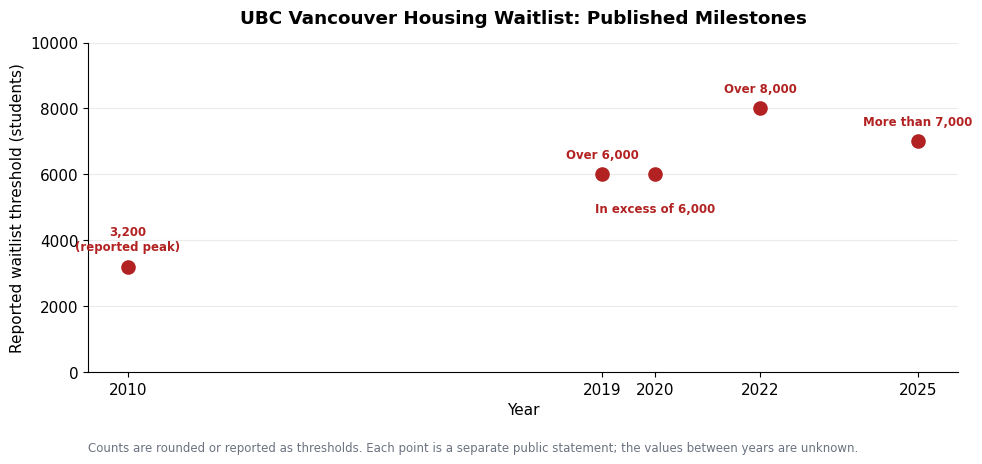

Waitlist milestones shown as separate observations.


In [8]:
# Plot published waitlist milestones as separate observations

w = waitlist.sort_values("year").copy()

milestone_labels = {
    2010: "3,200\n(reported peak)",
    2019: "Over 6,000",
    2020: "In excess of 6,000",
    2022: "Over 8,000",
    2025: "More than 7,000",
}

fig, ax = plt.subplots(figsize=(10, 5.5))

# Separate markers: no line connecting years with missing observations
ax.scatter(
    w["year"],
    w["waitlist_students"],
    s=90,
    color=WARN,
    zorder=3
)

# Give nearby milestones different label positions to avoid overlap
label_offsets = {
    2010: (0, 12),
    2019: (0, 12),
    2020: (0, -27),
    2022: (0, 12),
    2025: (0, 12),
}

for _, r in w.iterrows():
    year = int(r["year"])

    ax.annotate(
        milestone_labels.get(year, str(r["reported_as"])),
        (r["year"], r["waitlist_students"]),
        textcoords="offset points",
        xytext=label_offsets.get(year, (0, 12)),
        ha="center",
        fontsize=8.5,
        fontweight="bold",
        color=WARN
    )

ax.set_title(
    "UBC Vancouver Housing Waitlist: Published Milestones",
    fontweight="bold",
    pad=14
)

ax.set_ylabel("Reported waitlist threshold (students)")
ax.set_xlabel("Year")
ax.set_xticks(w["year"])
ax.set_ylim(0, 10000)

ax.text(
    0.0,
    -0.24,
    "Counts are rounded or reported as thresholds. "
    "Each point is a separate public statement; "
    "the values between years are unknown.",
    transform=ax.transAxes,
    fontsize=8.5,
    color="#6b7280",
    wrap=True
)

ax.grid(axis="x", visible=False)
fig.tight_layout(rect=[0, 0.09, 1, 1])

plt.savefig(
    FIG / "waitlist_milestones.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Waitlist milestones shown as separate observations.")

In [9]:
# Compare the international enrolment peak with published waitlist milestones.
# The waitlist figures are sparse statements, not a continuous annual series.

intl_peak = cap.loc[
    cap["international_headcount"].idxmax()
]

print("INTERNATIONAL ENROLMENT")
print(
    f"Peak: {intl_peak['international_headcount']:,} "
    f"in {intl_peak['academic_year']}"
)

print("\nPUBLISHED WAITLIST MILESTONES")

for _, row in w.sort_values("year").iterrows():
    print(f"{int(row['year'])}: {row['reported_as']}")

print("\nINTERPRETATION")
print(
    "International enrolment peaked in 2022/23, around the time "
    "a published waitlist statement reported over 8,000 students."
)
print(
    "Because the waitlist observations are sparse and use rounded "
    "or threshold-based counts, they do not establish the exact "
    "waitlist peak or a continuous trend."
)
print(
    "The timing alone does not demonstrate that international "
    "enrolment caused changes in waitlist pressure."
)

INTERNATIONAL ENROLMENT
Peak: 17,243 in 2022/23

PUBLISHED WAITLIST MILESTONES
2010: peak, as later characterised by UBC
2019: over 6,000
2020: in excess of 6,000
2022: over 8,000
2025: more than 7,000

INTERPRETATION
International enrolment peaked in 2022/23, around the time a published waitlist statement reported over 8,000 students.
Because the waitlist observations are sparse and use rounded or threshold-based counts, they do not establish the exact waitlist peak or a continuous trend.
The timing alone does not demonstrate that international enrolment caused changes in waitlist pressure.


**What this comparison tells us**

Reported residence capacity increased relative to enrolment between 2020/21 and 2024/25. At the same time, published waitlist milestones indicate substantial housing pressure.

However, the waitlist figures are isolated public statements rather than a continuous annual series. They cannot establish an exact rate of change, identify a definitive peak beyond what a source explicitly describes, or show how much pressure is attributable to housing supply, enrolment, application behaviour, or allocation policies.

International enrolment peaked in 2022/23, around the time of a high reported waitlist milestone. This timing is worth noting, but it does not prove a causal relationship.

The most defensible conclusion is that reported residence capacity increased relative to enrolment while public statements continued to indicate significant waitlist pressure. Better annual data on applications, eligibility, allocations, occupancy, and waitlist definitions would be needed to explain why that pressure persisted.


## 5. Signals from the Nearby Off-Campus Rental Market

When students seek housing off campus, purpose-built rental apartments are one part of the market they may consider. CMHC's Rental Market Survey provides a useful view of average rents and vacancy rates across Vancouver and selected zones near UBC.

The survey does not include UBC student residences and excludes secondary-market options such as rented condos and basement suites. These figures describe part of the rental market, not every option available to students. Source details and definitions are documented in `SOURCES.md`.


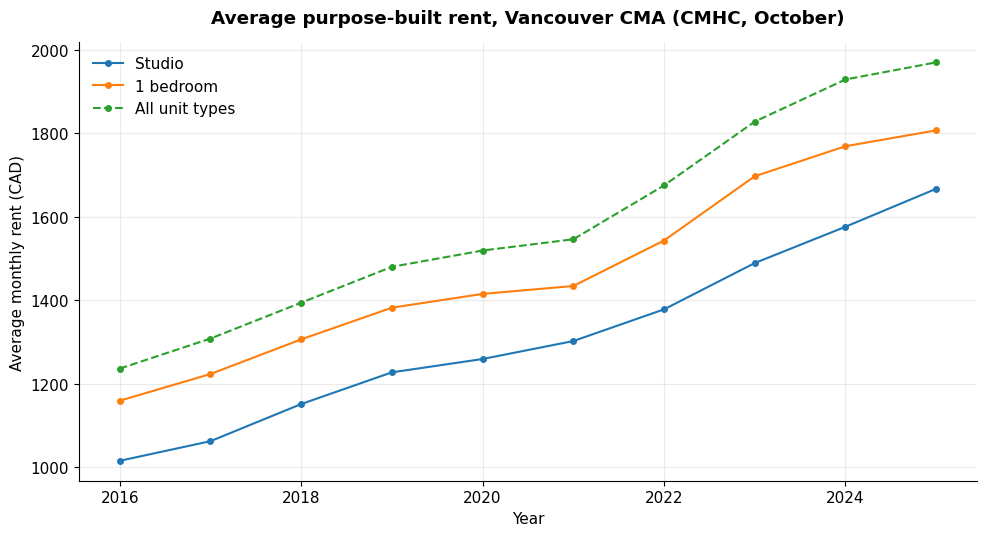

Studio rent 2016: $1,015  ->  2025: $1,667 (+64%)


In [10]:
fig, ax = plt.subplots()
for col, lab, ls in [("studio", "Studio", "-"), ("one_bed", "1 bedroom", "-"),
                     ("all_types", "All unit types", "--")]:
    ax.plot(rent["year"], rent[col], marker="o", markersize=4, linestyle=ls, label=lab)
ax.set_title("Average purpose-built rent, Vancouver CMA (CMHC, October)",
             fontweight="bold", pad=14)
ax.set_ylabel("Average monthly rent (CAD)"); ax.set_xlabel("Year")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG / "cmhc_rent_trajectory.png", dpi=200); plt.show()

r0, r1 = rent.iloc[0], rent.iloc[-1]
print(f"Studio rent {r0['year']}: ${r0['studio']:,}  ->  {r1['year']}: ${r1['studio']:,} "
      f"({(r1['studio']/r0['studio']-1)*100:+.0f}%)")

Across the Vancouver CMA, the average monthly studio rent rose from **$1,015 in 2016 to $1,667 in 2025**, an increase of about **64% in nominal terms**. This change is not adjusted for inflation and covers purpose-built rental housing, not the entire rental market.


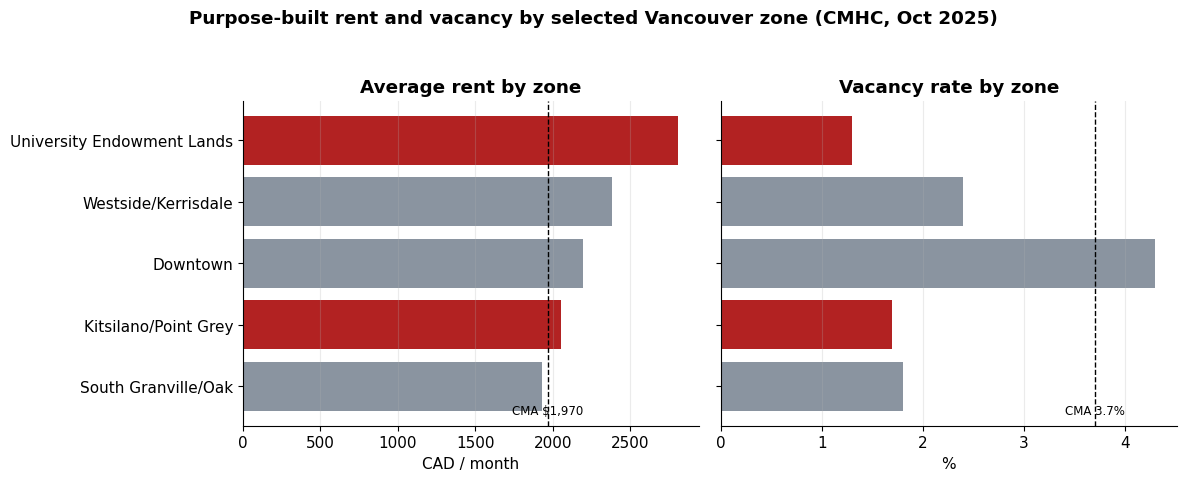

University Endowment Lands     rent $2,805 (+42% vs CMA), vacancy 1.3% (CMA 3.7%), 2,082 units
Kitsilano/Point Grey           rent $2,051 (+4% vs CMA), vacancy 1.7% (CMA 3.7%), 7,632 units


In [11]:
z = zones.set_index("zone_name")
cma = z.loc["Vancouver CMA"]
near = z.drop(index="Vancouver CMA").copy()
near["rent_vs_cma_pct"] = (near["avg_rent"] / cma["avg_rent"] - 1) * 100

fig, (axA, axB) = plt.subplots(1, 2, figsize=(12, 4.6))
order = near.sort_values("avg_rent")

axA.barh(order.index, order["avg_rent"], color=[WARN if i in
         ("University Endowment Lands", "Kitsilano/Point Grey") else MUTE for i in order.index])
axA.axvline(cma["avg_rent"], color="black", linestyle="--", linewidth=1)
axA.annotate(f"CMA ${cma['avg_rent']:,.0f}", (cma["avg_rent"], -0.45),
             fontsize=8.5, ha="center")
axA.set_title("Average rent by zone", fontweight="bold"); axA.set_xlabel("CAD / month")
axA.grid(axis="y", visible=False)

axB.barh(order.index, order["vacancy_rate_pct"], color=[WARN if i in
         ("University Endowment Lands", "Kitsilano/Point Grey") else MUTE for i in order.index])
axB.axvline(cma["vacancy_rate_pct"], color="black", linestyle="--", linewidth=1)
axB.annotate(f"CMA {cma['vacancy_rate_pct']}%", (cma["vacancy_rate_pct"], -0.45),
             fontsize=8.5, ha="center")
axB.set_title("Vacancy rate by zone", fontweight="bold"); axB.set_xlabel("%")
axB.tick_params(axis="y", labelleft=False); axB.grid(axis="y", visible=False)

plt.suptitle("Purpose-built rent and vacancy by selected Vancouver zone (CMHC, Oct 2025)",
             fontweight="bold", y=1.04)
plt.tight_layout(); plt.savefig(FIG / "zone_rent_vacancy.png", dpi=200, bbox_inches="tight")
plt.show()

for n in ["University Endowment Lands", "Kitsilano/Point Grey"]:
    r = z.loc[n]
    print(f"{n:30s} rent ${r['avg_rent']:,.0f} ({(r['avg_rent']/cma['avg_rent']-1)*100:+.0f}% vs CMA), "
          f"vacancy {r['vacancy_rate_pct']}% (CMA {cma['vacancy_rate_pct']}%), "
          f"{r['rental_universe']:,} units")

The University Endowment Lands zone, which includes UBC, had an average monthly rent of **$2,805**, approximately **42% above** the Vancouver CMA average of $1,970. Its reported vacancy rate was **1.3%**, compared with 3.7% across the CMA.

Kitsilano/Point Grey also showed a tight rental market, with a 1.7% vacancy rate and an average rent of $2,051.

Among the nearby zones included in this comparison, the University Endowment Lands had the highest average rent and lowest vacancy rate. This suggests that the surrounding purpose-built rental market was relatively expensive and had limited vacancies in October 2025.

The zone's 2,082 rental units represent the **total surveyed rental stock**, not 2,082 vacant or student-accessible units. We also cannot directly compare this number with the university waitlist to determine whether the private rental market can accommodate those students. Waitlisted students have different housing needs, budgets, and alternatives, and CMHC does not measure all housing options they may use.

These results provide context for the housing pressures students may face, but they do not establish the affordability or availability of every option near campus.

## 6. Residence Cost Context


In [12]:
# Compare the residence room fee, mandatory meal plan,
# and Vancouver CMA studio rent.

f2 = fees.copy()

f2["monthly_room_fee"] = (
    f2["room_fee_cad"] / f2["months"]
)

f2["monthly_meal_plan"] = (
    f2["mandatory_meal_plan_cad"].fillna(0)
    / f2["months"]
)

f2["monthly_room_plus_meal_plan"] = (
    f2["room_fee_cad"]
    + f2["mandatory_meal_plan_cad"].fillna(0)
) / f2["months"]

single = f2.loc[
    (f2["residence"] == "Totem Park")
    & (f2["room_type"] == "Single Room")
].iloc[0]

latest_rent = rent.sort_values("year").iloc[-1]

room_only = single["monthly_room_fee"]
meal_plan = single["monthly_meal_plan"]
room_plus_meals = single["monthly_room_plus_meal_plan"]
studio_rent = latest_rent["studio"]

cost_comparison = pd.DataFrame({
    "Option": [
        "Totem Park single room",
        "Mandatory meal plan",
        "Room + meal plan",
        f"Vancouver CMA studio rent ({int(latest_rent['year'])})"
    ],
    "Monthly equivalent (CAD)": [
        room_only,
        meal_plan,
        room_plus_meals,
        studio_rent
    ]
})

print("RESIDENCE COST COMPARISON")
display(cost_comparison.round(2))

print(
    f"\nRoom + meal plan: ${room_plus_meals:,.0f}/month"
)
print(
    f"CMA studio rent:  ${studio_rent:,.0f}/month"
)
print(
    f"Difference:       ${room_plus_meals - studio_rent:,.0f}/month"
)

print(
    "\nImportant: this is not a like-for-like affordability comparison. "
    "The residence price includes a mandatory meal plan; studio rent does not."
)

RESIDENCE COST COMPARISON


,Option,Monthly equivalent (CAD)
0,Totem Park single room,991.88
1,Mandatory meal plan,964.04
2,Room + meal plan,1955.92
3,Vancouver CMA studio rent (2025),1667.00



Room + meal plan: $1,956/month
CMA studio rent:  $1,667/month
Difference:       $289/month

Important: this is not a like-for-like affordability comparison. The residence price includes a mandatory meal plan; studio rent does not.


### How to interpret the comparison

The 2026/27 Totem Park single-room fee is approximately $992 per month when the eight-month Winter Session contract is spread across its duration. The mandatory meal plan adds approximately $964 per month, bringing the combined room and meal-plan cost to about $1,956 per month.

For context, CMHC reported an average studio rent of $1,667 per month across the Vancouver CMA in October 2025. Although the room fee alone is lower, the combined residence fee and meal plan is higher than this studio-rent benchmark.

This is not a like-for-like affordability comparison. Totem Park is a first-year residence with a mandatory meal plan, whereas a studio is a self-contained unit whose rent does not include food. The figures also cover different periods and geographic areas. They illustrate the importance of considering total required costs rather than room fees alone; they do not establish which housing option is more affordable overall or for upper-year students.


## 7. Planned Expansion in Context

UBC's Housing Action Plan commits to at least 3,300 new beds plus 1,000 replacement beds on the Vancouver campus by the mid-2030s. The plan targets at least 17,300 beds system-wide. The comparison below is intended to show scale relative to the published 2025 waitlist statement, not to predict when housing pressure will ease.


PLANNED EXPANSION AND REPORTED WAITLIST
Planned new Vancouver beds: 3,300
Latest waitlist statement: more than 7,000
Planned new beds are less than 47.2% of the reported waitlist threshold.

SENSITIVITY TO THE BED-COUNT DISCREPANCY
Average net bed-count change, 2020–2024 (published totals): 471 beds/year
Average net bed-count change, 2020–2024 (alternative 2024 total): 372 beds/year

These are historical averages based on two dated totals, not annual construction rates or forecasts.


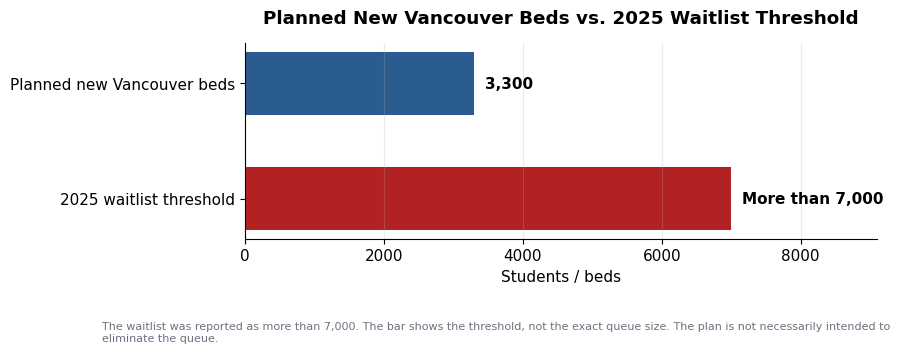

In [13]:
# Compare planned new beds with the published 2025 waitlist threshold.
# This is a scale comparison, not a forecast of waitlist clearance.

PLANNED_NEW = 3300  # New Vancouver beds committed by the plan

latest_waitlist = w.sort_values("year").iloc[-1]
QUEUE_THRESHOLD = int(latest_waitlist["waitlist_students"])
QUEUE_DESCRIPTION = str(latest_waitlist["reported_as"])

# Historical average net change between two dated capacity observations.
# The 2020 bed count is approximate, and the 2024 total is unreconciled.
beds_2024_alternative = int(b.loc[2023] + 282)

reported_avg_change = (
    b.loc[2024] - b.loc[2020]
) / (2024 - 2020)

alternative_avg_change = (
    beds_2024_alternative - b.loc[2020]
) / (2024 - 2020)

share_upper_bound = PLANNED_NEW / QUEUE_THRESHOLD * 100
# Since the actual reported queue is greater than 7,000, round the upper bound up.
share_upper_bound_display = np.ceil(share_upper_bound * 10) / 10

print("PLANNED EXPANSION AND REPORTED WAITLIST")
print(f"Planned new Vancouver beds: {PLANNED_NEW:,}")
print(f"Latest waitlist statement: {QUEUE_DESCRIPTION}")
print(
    f"Planned new beds are less than {share_upper_bound_display:.1f}% "
    "of the reported waitlist threshold."
)

print("\nSENSITIVITY TO THE BED-COUNT DISCREPANCY")
print(
    f"Average net bed-count change, 2020–2024 "
    f"(published totals): {reported_avg_change:,.0f} beds/year"
)
print(
    f"Average net bed-count change, 2020–2024 "
    f"(alternative 2024 total): {alternative_avg_change:,.0f} beds/year"
)

print(
    "\nThese are historical averages based on two dated totals, "
    "not annual construction rates or forecasts."
)

# Visual comparison: the waitlist bar represents only the published threshold.
fig, ax = plt.subplots(figsize=(9, 3.5))

labels = [
    "2025 waitlist threshold",
    "Planned new Vancouver beds"
]
values = [QUEUE_THRESHOLD, PLANNED_NEW]
colors = [WARN, ACCENT]

ax.barh(labels, values, color=colors, height=0.55)

ax.annotate(
    f"{QUEUE_DESCRIPTION.capitalize()}",
    (QUEUE_THRESHOLD, 0),
    xytext=(8, 0),
    textcoords="offset points",
    va="center",
    fontweight="bold"
)

ax.annotate(
    f"{PLANNED_NEW:,}",
    (PLANNED_NEW, 1),
    xytext=(8, 0),
    textcoords="offset points",
    va="center",
    fontweight="bold"
)

ax.set_title(
    "Planned New Vancouver Beds vs. 2025 Waitlist Threshold",
    fontweight="bold",
    pad=14
)
ax.set_xlabel("Students / beds")
ax.set_xlim(0, QUEUE_THRESHOLD * 1.3)
ax.grid(axis="y", visible=False)

fig.text(
    0.12, 0.01,
    "The waitlist was reported as more than 7,000. "
    "The bar shows the threshold, not the exact queue size. "
    "The plan is not necessarily intended to eliminate the queue.",
    fontsize=8,
    color="#6b7280",
    wrap=True
)

fig.tight_layout(rect=[0, 0.12, 1, 1])
plt.savefig(
    FIG / "planned_vs_queue.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

The Housing Action Plan commits to 3,300 new Vancouver beds by the mid-2030s, alongside 1,000 replacement beds. The new-bed commitment is less than 47.2% of the published 2025 waitlist threshold of more than 7,000 students.

This comparison illustrates the scale of the planned expansion relative to reported waitlist pressure; it does not mean that the plan was intended to eliminate the entire queue. The waitlist is a point-in-time measure, its counting basis is unpublished, and newly built beds may serve different groups of students.

Historical bed-count growth also depends on which published 2024 total is used. Because the reported totals do not reconcile, a precise timeline for resolving housing pressure cannot be established from these data.

## Findings

1. **Reported housing capacity increased relative to enrolment.** Using published bed totals, capacity rose from approximately 205 beds per 1,000 students in 2020/21 to 228 in 2024/25. An alternative calculation gives approximately 221 beds per 1,000 students. Both indicate an increase, but these ratios measure capacity, not actual occupancy.

2. **Published waitlist milestones indicate continued housing pressure.** Public statements reported a historical peak of 3,200 students in 2010, over 8,000 in 2022, and more than 7,000 in 2025. These are rounded or threshold-based observations, not a continuous annual series. They do not establish an exact peak or a precise growth rate.

3. **International enrolment peaked around the period of a high waitlist milestone.** International enrolment rose 42% from 2015/16 to its 2022/23 peak, then fell by about 5% by 2024/25. This timing is worth noting, but it does not prove that international enrolment caused changes in waitlist pressure.

4. **The nearby purpose-built rental market showed affordability and availability pressure.** In October 2025, the University Endowment Lands zone had an average rent of $2,805 and a vacancy rate of 1.3%, compared with $1,970 and 3.7% across the Vancouver CMA. These figures describe part of the rental market, not every option available to students.

5. **Residence costs need to be considered alongside included services.** A Totem Park single room costs approximately $992 per month before its mandatory meal plan, while the combined cost is approximately $1,956. The Vancouver CMA average studio rent was $1,667 in October 2025. These are illustrative benchmarks, not directly comparable total living costs.

6. **Planned expansion does not establish when waitlist pressure will ease.** The commitment to add 3,300 new Vancouver beds is less than 47.2% of the reported 2025 waitlist threshold of more than 7,000 students. This illustrates the scale of the plan relative to reported pressure, but it does not predict how the waitlist will change.

### Overall conclusion

UBC Vancouver's reported residence capacity increased relative to enrolment, while public statements continued to indicate significant waitlist pressure. Nearby rental data also suggests that off-campus purpose-built housing can be expensive and have limited vacancies.

However, these aggregate figures cannot show exactly which students need housing, why they remain on a waitlist, or how many would use new residence beds. Better annual data on applications, eligibility, allocations, occupancy, and waitlist definitions would help answer those questions.

## Limitations

- Bed and waitlist figures are dated public statements, not continuous annual series.
- Waitlist counts are rounded or reported as thresholds, and their counting basis is not publicly documented.
- UBC's published bed totals contain an unresolved 396-bed difference.
- Timing relationships do not establish causation.
- CMHC measures purpose-built rental housing and excludes secondary-market options such as rented condos and basement suites.
- Zone-level rent and vacancy figures are a single-period snapshot from 2025.
- Residence fees represent a 2026/27 snapshot and the cost comparison includes different services and periods.
- Applicant-level demand, eligibility, allocation, and occupancy data are not available here. The analysis therefore describes aggregate conditions, not individual students' housing outcomes.
